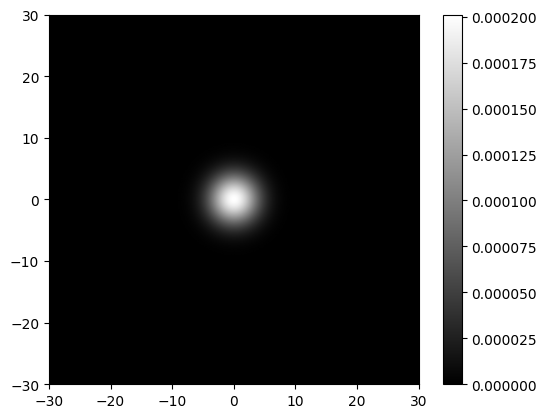

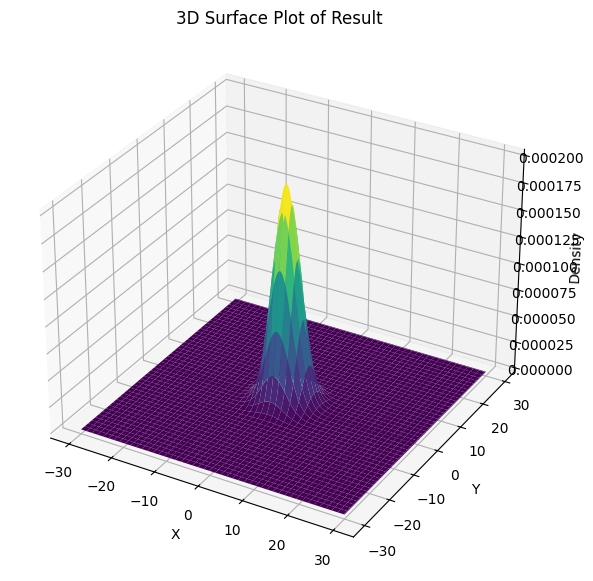

In [5]:
import numpy as np
from scipy.signal import convolve2d
from mpl_toolkits.mplot3d import Axes3D
r = 1.0
intervals = 20
mult = 30
eps = 1e-3
L = mult * r
L_intervals = mult * intervals
L_x = np.linspace(-L, L, L_intervals + 1)
L_y = np.linspace(-L, L, L_intervals + 1)
L_xx, L_yy = np.meshgrid(L_x, L_y)
L_circle = ((L_xx**2 + L_yy**2) <= r*(1+eps)).astype(float)
L_circle /= np.sum(L_circle)


r_x = np.linspace(-r, 1, intervals+1)
r_y = np.linspace(-r, 1, intervals+1)
r_xx, r_yy = np.meshgrid(r_x, r_y)
r_circle = ((r_xx**2 + r_yy**2) <= r*(1+eps)).astype(float)
r_circle /= np.sum(r_circle)

# Convolve the fine circle with the coarse circle
result = L_circle.copy()
# print("shape:", result.shape)
for _ in range(30):
    result = convolve2d(result, r_circle, mode='same', boundary='fill', fillvalue=0)
    result /= np.sum(result)
    # print("shape:", result.shape)

# Normalize the result so that total area is 1
import matplotlib.pyplot as plt
plt.imshow(result, extent= (-L,L,-L,L) ,origin='lower', cmap='gray')
plt.colorbar()
plt.show()

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
X, Y = L_xx, L_yy
ax.plot_surface(X, Y, result, cmap='viridis', edgecolor='none')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Density')
ax.set_title('3D Surface Plot of Result')
plt.show()


Estimated mean: [np.float64(1.457167719820518e-15), np.float64(1.9984014443252818e-15)]
Estimated covariance matrix:
 [[ 7.82921136e+00 -1.04263257e-16]
 [-1.04263257e-16  7.82921136e+00]]
L1 error between result and expected Gaussian: 0.006745206240526414


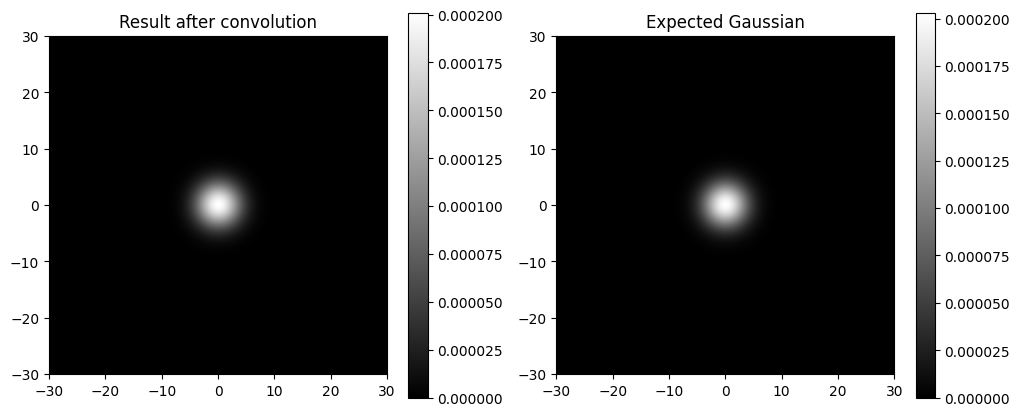

In [44]:
from scipy.stats import multivariate_normal

# Calculate the mean (should be at the center)
mean_x = np.sum(L_xx * result)
mean_y = np.sum(L_yy * result)

# Calculate the variances
var_x = np.sum(((L_xx - mean_x) ** 2) * result)
var_y = np.sum(((L_yy - mean_y) ** 2) * result)
cov_xy = np.sum((L_xx - mean_x) * (L_yy - mean_y) * result)

mean = [mean_x, mean_y]
cov = [[var_x, cov_xy], [cov_xy, var_y]]

print("Estimated mean:", mean)
print("Estimated covariance matrix:\n", np.array(cov))

# Generate the expected Gaussian
gaussian = multivariate_normal(mean=mean, cov=cov)
expected = gaussian.pdf(np.dstack((L_xx, L_yy)))
expected /= np.sum(expected)  # Normalize the expected Gaussian

# Calculate the mean squared error between the two distributions
mse = np.sum(np.abs(result - expected))
print("L1 error between result and expected Gaussian:", mse)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.title("Result after convolution")
plt.imshow(result, extent=(-L, L, -L, L), origin='lower', cmap='gray')
plt.colorbar()

plt.subplot(1,2,2)
plt.title("Expected Gaussian")
plt.imshow(expected, extent=(-L, L, -L, L), origin='lower', cmap='gray')
plt.colorbar()
plt.show()